In [ ]:
import warnings
warnings.filterwarnings("ignore")      
SEED = 42

In [2]:
import os
RAW_FILE = "hybrid_student_performance_1200.csv"
TARGET_COLS = ["cgpa_category", "attendance_percentage"]   
ADD_DEMO_DUPLICATES = False                                

MID = {
    "study_hours_daily":     {"Less than 1 hour": 0.5, "1–2 hours": 1.5, "More than 2 hours": 3.0},
    "sleep_hours":           {"4–5 hours": 4.5, "6–7 hours": 6.5, "More than 8 hours": 9.0},
    "attendance_percentage": {"Less than 50%": 25, "50% – 65%": 57.5, "66% – 75%": 70.5, "76% – 85%": 80.5, "Above 85%": 92.5},
    "cgpa_category":         {"5.0 – 6.9": 5.95, "7.0 – 8.4": 7.7, "8.5 – 9.4": 8.95, "9.5 – 10.0": 9.75},
}
FEATURE_NAME = {"study_hours_daily": "study_hours", "sleep_hours": "sleep_hours",
                "attendance_percentage": "attendance_rate", "cgpa_category": "previous_gpa"}
TO_100 = {"cgpa_category": 10, "attendance_percentage": 1, "study_hours_daily": None, "sleep_hours": None}   


In [3]:
if os.path.exists(RAW_FILE):
    import pandas as pd
    raw = pd.read_csv(RAW_FILE)
    mid = {c: raw[c].map(MID[c]) for c in MID}                    

    out = pd.DataFrame({"student_id": raw["student_id"]})
    for c in MID:
        if c not in TARGET_COLS:                                   
            out[FEATURE_NAME[c]] = mid[c]
    for c in ["stress_level", "daily_productivity", "energy_level"]:
        out[c] = raw[c]
    out["school_code"] = raw["program_stream"] + " | " + raw["year_class"]
    out["enrollment_date"] = pd.to_datetime(raw["timestamp"], format="%m/%d/%Y %H:%M:%S").dt.strftime("%Y-%m-%d %H:%M:%S")


    out["final_score"] = pd.concat([mid[c] * TO_100[c] for c in TARGET_COLS], axis=1).mean(axis=1, skipna=False)

    if ADD_DEMO_DUPLICATES:
        copies = out.sample(50, random_state=1).copy()
        copies["student_id"] = [f"DUP{i:03d}" for i in range(50)]
        out = pd.concat([out, copies]).reset_index(drop=True)

    out.to_csv("student_performance.csv", index=False)
    print("student_performance.csv created:", out.shape)
    print("Target built from:", TARGET_COLS, "| features:", [c for c in out.columns if c not in ("student_id", "school_code", "enrollment_date", "final_score")])
    display(out[["final_score"]].describe().T.round(2))
else:
    print(RAW_FILE, "not found -> using the existing student_performance.csv")

student_performance.csv created: (1200, 9)
Target built from: ['cgpa_category', 'attendance_percentage'] | features: ['study_hours', 'sleep_hours', 'stress_level', 'daily_productivity', 'energy_level']


,count,mean,std,min,25%,50%,75%,max
final_score,1200.0,74.87,13.33,42.25,67.25,73.75,85.0,95.0


In [4]:
#A.1
import pandas as pd

df = pd.read_csv("student_performance.csv")
print("Shape (rows, columns):", df.shape)
display(df.head())
print("\nData types:\n", df.dtypes)
display(df.describe().round(2))
print("\nMissing values per column:\n", df.isna().sum())

Shape (rows, columns): (1200, 9)


,student_id,study_hours,sleep_hours,stress_level,daily_productivity,energy_level,school_code,enrollment_date,final_score
0,STU0001,0.5,6.5,4.0,2.0,4.0,BCA | Second Year (SY),2026-03-29 20:54:43,91.00
1,STU0002,1.5,6.5,3.0,1.0,2.0,BCA | Second Year (SY),2026-03-29 21:20:15,85.00
2,STU0003,1.5,6.5,5.0,2.0,4.0,BCA | Second Year (SY),2026-03-29 21:21:35,42.25
3,STU0004,1.5,6.5,2.0,3.0,3.0,BCA | Second Year (SY),2026-03-29 21:27:44,91.00
4,STU0005,1.5,4.5,5.0,2.0,3.0,BCA | Second Year (SY),2026-03-29 22:05:14,85.00



Data types:
 student_id                str
study_hours           float64
sleep_hours           float64
stress_level          float64
daily_productivity    float64
energy_level          float64
school_code               str
enrollment_date           str
final_score           float64
dtype: object


,study_hours,sleep_hours,stress_level,daily_productivity,energy_level,final_score
count,1200.00,1145.00,1165.00,1166.00,1172.00,1200.00
mean,1.40,6.85,3.15,2.69,3.23,74.87
std,0.87,1.44,1.19,1.18,1.15,13.33
min,0.50,4.50,1.00,1.00,1.00,42.25
25%,0.50,6.50,2.00,2.00,2.00,67.25
50%,1.50,6.50,3.00,3.00,3.00,73.75
75%,1.50,9.00,4.00,3.00,4.00,85.00
max,3.00,9.00,5.00,5.00,5.00,95.00



Missing values per column:
 student_id             0
study_hours            0
sleep_hours           55
stress_level          35
daily_productivity    34
energy_level          28
school_code            0
enrollment_date        0
final_score            0
dtype: int64


In [5]:
#A.2
cols_no_id = [c for c in df.columns if c != "student_id"]

print("Duplicated rows WITH student_id   :", df.duplicated().sum())
print("Duplicated rows WITHOUT student_id:", df.duplicated(subset=cols_no_id).sum())

Duplicated rows WITH student_id   : 0
Duplicated rows WITHOUT student_id: 0


In [6]:
#A.3
import matplotlib.pyplot as plt

In [7]:
if "parent_education" in df.columns:
    df["parent_education_num"] = df["parent_education"].map({"low": 0, "medium": 1, "high": 2})
NUM = [c for c in df.select_dtypes("number").columns if c != "final_score"]
print("Numeric features:", NUM)

Numeric features: ['study_hours', 'sleep_hours', 'stress_level', 'daily_productivity', 'energy_level']


,correlation with final_score
sleep_hours,-0.026
energy_level,0.025
stress_level,0.047
daily_productivity,0.091
study_hours,0.256


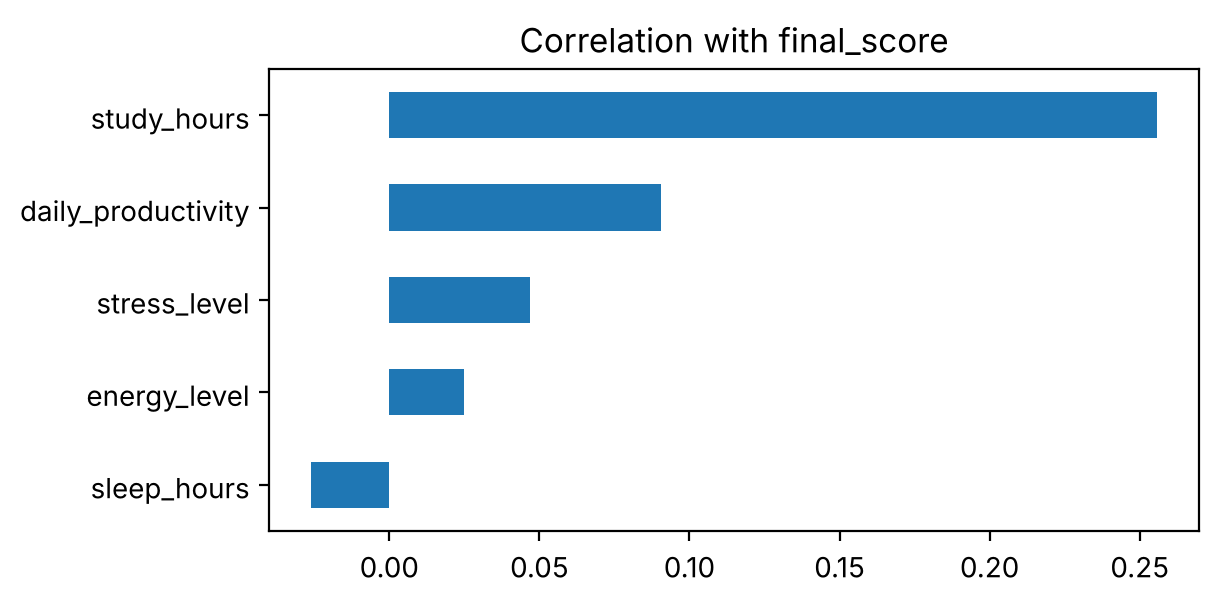

Strongest: study_hours | Weakest: energy_level


In [8]:
corr = df[NUM + ["final_score"]].corr()["final_score"].drop("final_score").sort_values()
display(corr.round(3).to_frame("correlation with final_score"))

corr.plot(kind="barh", title="Correlation with final_score", figsize=(6, 3))
plt.show()
print("Strongest:", corr.abs().idxmax(), "| Weakest:", corr.abs().idxmin())

In [9]:
#A.4
counts = df["school_code"].value_counts()
print("Number of schools:", len(counts))
print("Schools with fewer than 10 observations:", (counts < 10).sum())

Number of schools: 42
Schools with fewer than 10 observations: 12


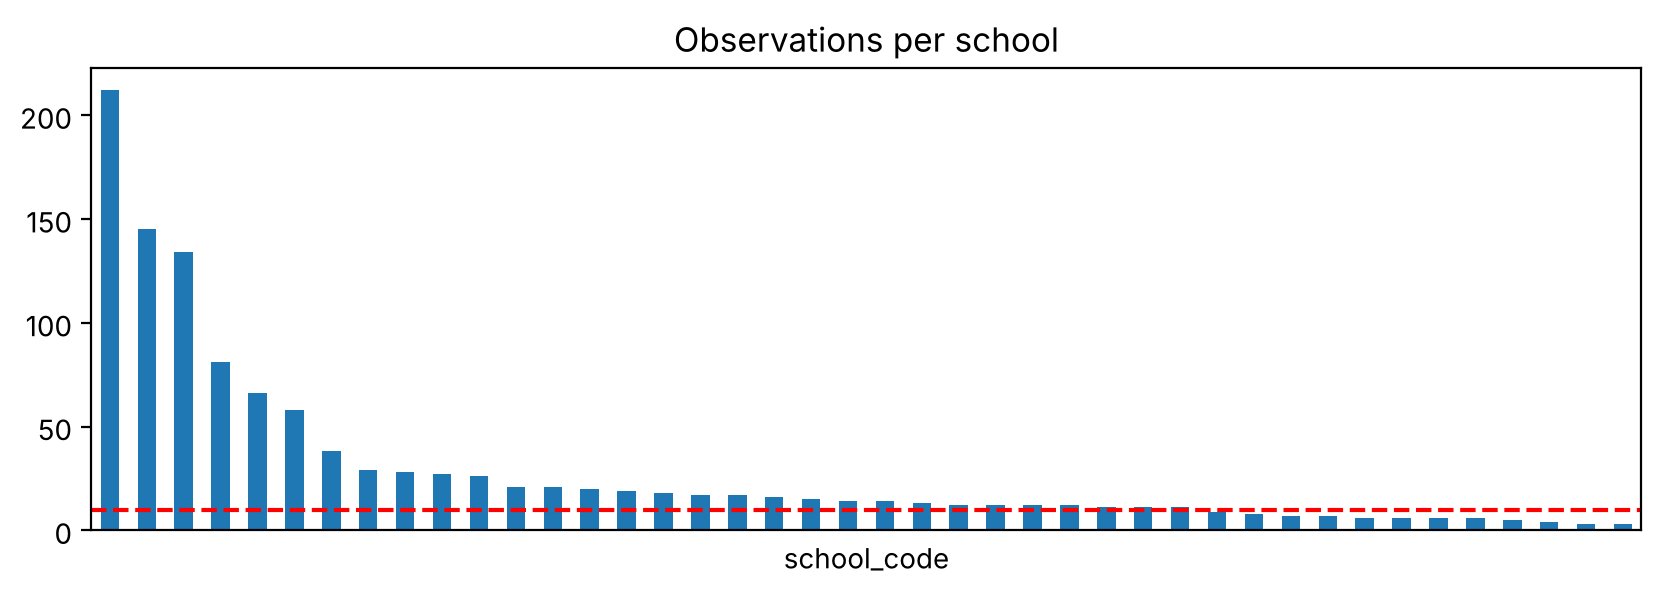

In [10]:
counts.plot(kind="bar", figsize=(10, 3), title="Observations per school")
plt.axhline(10, color="red", linestyle="--"); plt.xticks([]); plt.show()

In [11]:
#A.5
import numpy as np

df["enrollment_date"] = pd.to_datetime(df["enrollment_date"])
d = df.dropna(subset=["final_score"]).sort_values("enrollment_date")

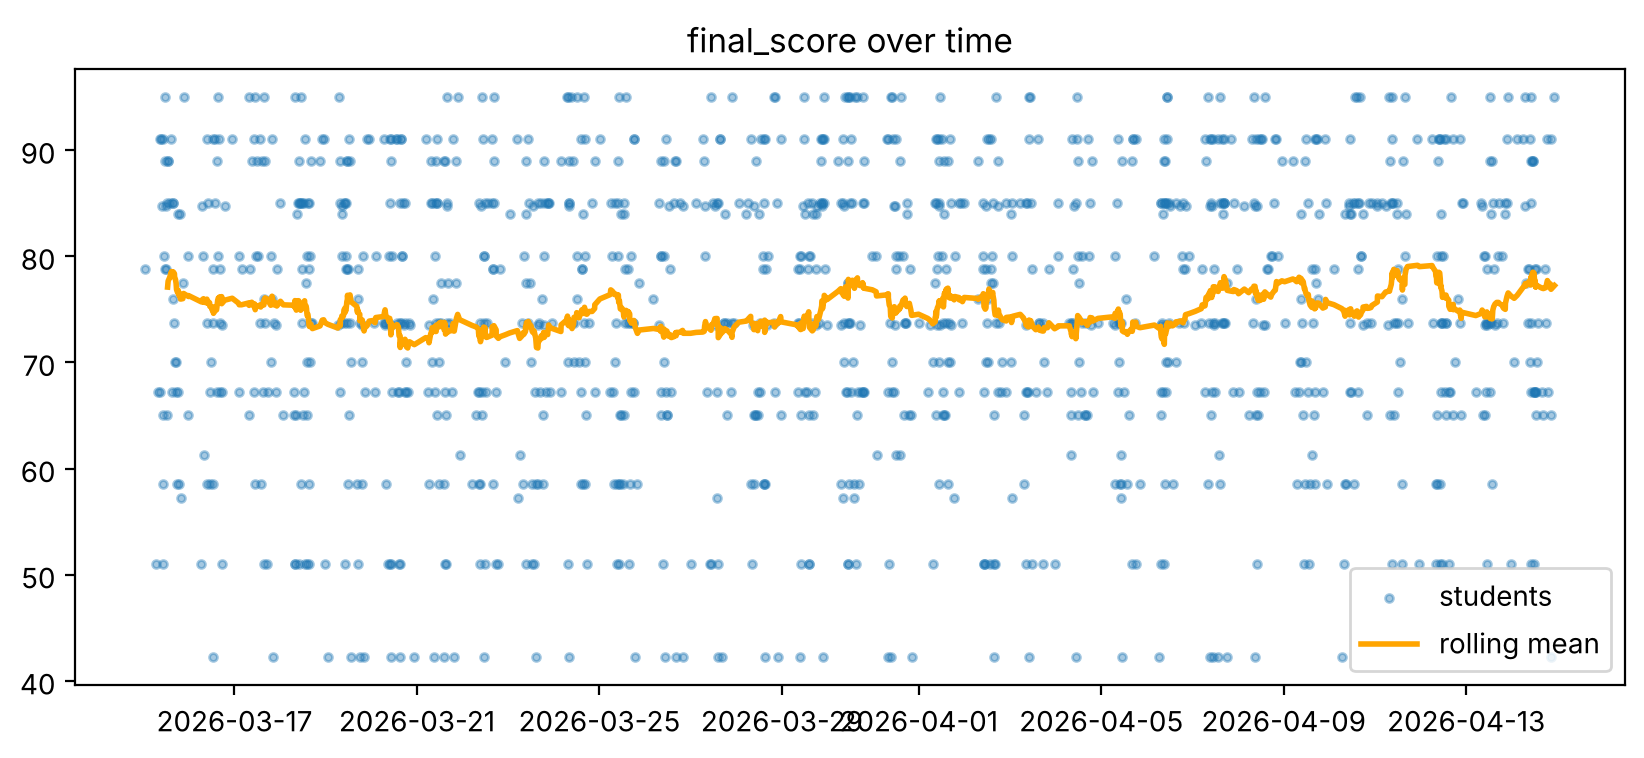

In [12]:
plt.figure(figsize=(10, 4))
plt.scatter(d["enrollment_date"], d["final_score"], s=8, alpha=0.4, label="students")
plt.plot(d["enrollment_date"], d["final_score"].rolling(60, min_periods=20).mean(), color="orange", lw=2, label="rolling mean")
plt.title("final_score over time"); plt.legend(); plt.show()

In [13]:
days = (d["enrollment_date"] - d["enrollment_date"].min()).dt.days
print(f"Data span: {days.max()} days | average trend: {np.polyfit(days, d['final_score'], 1)[0] * 30:+.3f} points per 30 days")

Data span: 30 days | average trend: +2.290 points per 30 days

In [14]:
#B.0
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

In [15]:
def rmse(y, pred):
    return np.sqrt(mean_squared_error(y, pred))

In [16]:
data = df.drop(columns=["student_id"]).dropna().copy()
data["school_code_enc"] = data["school_code"].astype("category").cat.codes
data = data.sort_values("enrollment_date", kind="mergesort").reset_index(drop=True)    

In [17]:
TARGET = "final_score"
FEATURES = NUM + ["school_code_enc"]

In [18]:
def split_random(d):
    return train_test_split(d, test_size=0.2, random_state=SEED)

def split_chrono(d):
    cut = int(len(d) * 0.8)
    return d.iloc[:cut], d.iloc[cut:]             

def fit_tree(train, test):
    m = DecisionTreeRegressor(random_state=SEED).fit(train[FEATURES], train[TARGET])
    return rmse(train[TARGET], m.predict(train[FEATURES])), rmse(test[TARGET], m.predict(test[FEATURES]))

summary = []     
print("Rows:", len(data), "| Features:", FEATURES)

Rows: 1049 | Features: ['study_hours', 'sleep_hours', 'stress_level', 'daily_productivity', 'energy_level', 'school_code_enc']


In [19]:
#B.1
rows = []
for name, split in [("Random split 80/20", split_random), ("Chronological split 80/20", split_chrono)]:
    train_, test_ = split(data)
    tr_rmse, te_rmse = fit_tree(train_, test_)
    summary.append(("B.1", name, tr_rmse, te_rmse))
    rows.append([name, tr_rmse, te_rmse])

display(pd.DataFrame(rows, columns=["Strategy", "Training RMSE", "Testing RMSE"]).round(3))

,Strategy,Training RMSE,Testing RMSE
0,Random split 80/20,4.025,18.804
1,Chronological split 80/20,3.866,18.750


In [20]:
#B.2
def n_leaked(train_, test_):
    return len(test_[cols_no_id].merge(train_[cols_no_id].drop_duplicates(), on=cols_no_id))

In [21]:
nodup = data.drop_duplicates(subset=cols_no_id)
rows = []

In [22]:
for sname, split in [("Random", split_random), ("Chronological", split_chrono)]:
#a
    train_, test_ = split(data)
    train_, test_ = train_.drop_duplicates(subset=cols_no_id), test_.drop_duplicates(subset=cols_no_id)
    a_tr, a_te = fit_tree(train_, test_)
    rows.append([f"{sname}: split THEN remove duplicates", n_leaked(train_, test_), a_tr, a_te])
    summary.append(("B.2", f"{sname}: split THEN remove duplicates", a_tr, a_te))
#b
    train_, test_ = split(nodup)
    b_tr, b_te = fit_tree(train_, test_)
    rows.append([f"{sname}: remove duplicates THEN split", n_leaked(train_, test_), b_tr, b_te])
    summary.append(("B.2", f"{sname}: remove duplicates THEN split", b_tr, b_te))

display(pd.DataFrame(rows, columns=["Strategy", "Test rows also in train", "Training RMSE", "Testing RMSE"]).round(3))

,Strategy,Test rows also in train,Training RMSE,Testing RMSE
0,Random: split THEN remove duplicates,0,4.025,18.804
1,Random: remove duplicates THEN split,0,4.025,18.804
2,Chronological: split THEN remove duplicates,0,3.866,18.750
3,Chronological: remove duplicates THEN split,0,3.866,18.750


In [23]:
clean = data.drop_duplicates(subset=cols_no_id).reset_index(drop=True)
train, test = split_chrono(clean)
n = len(train)

In [24]:
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print("Train:", len(train), "rows |", train["enrollment_date"].min().date(), "->", train["enrollment_date"].max().date())
print("Test :", len(test),  "rows |", test["enrollment_date"].min().date(),  "->", test["enrollment_date"].max().date())

Train: 839 rows | 2026-03-15 -> 2026-04-08
Test : 210 rows | 2026-04-08 -> 2026-04-14


In [25]:
#B.3
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsRegressor

In [26]:
models = {"Decision Tree": lambda: DecisionTreeRegressor(random_state=SEED),
          "k-NN (k=5)":    lambda: KNeighborsRegressor(n_neighbors=5)}
rows = []

In [27]:
for name, make in models.items():

    scaled = StandardScaler().fit_transform(clean[FEATURES])
    m = make().fit(scaled[:n], y_train)
    leak = (rmse(y_train, m.predict(scaled[:n])), rmse(y_test, m.predict(scaled[n:])))
 
    pipe = make_pipeline(StandardScaler(), make()).fit(X_train, y_train)
    ok = (rmse(y_train, pipe.predict(X_train)), rmse(y_test, pipe.predict(X_test)))

    summary.append(("B.3", f"{name} - scaler on ALL data (leak)", *leak))
    summary.append(("B.3", f"{name} - scaler on TRAIN only (Pipeline)", *ok))
    rows.append([name, leak[1], ok[1], ok[1] - leak[1]])

In [28]:
display(pd.DataFrame(rows, columns=["Model", "Testing RMSE (leaky)", "Testing RMSE (Pipeline)", "Difference"]).round(4))

,Model,Testing RMSE (leaky),Testing RMSE (Pipeline),Difference
0,Decision Tree,18.7373,18.4739,-0.2633
1,k-NN (k=5),13.3995,13.5352,0.1357


In [29]:
display(pd.DataFrame(summary, columns=["Part", "Strategy", "Training RMSE", "Testing RMSE"]).round(3))

,Part,Strategy,Training RMSE,Testing RMSE
0,B.1,Random split 80/20,4.025,18.804
1,B.1,Chronological split 80/20,3.866,18.750
2,B.2,Random: split THEN remove duplicates,4.025,18.804
3,B.2,Random: remove duplicates THEN split,4.025,18.804
4,B.2,Chronological: split THEN remove duplicates,3.866,18.750
5,B.2,Chronological: remove duplicates THEN split,3.866,18.750
6,B.3,Decision Tree - scaler on ALL data (leak),3.866,18.737
7,B.3,Decision Tree - scaler on TRAIN only (Pipeline),3.866,18.474
8,B.3,k-NN (k=5) - scaler on ALL data (leak),11.869,13.400
9,B.3,k-NN (k=5) - scaler on TRAIN only (Pipeline),11.847,13.535


In [30]:
#C.1
depths = [1, 2, 3, 5, 10, 20, None]
rows = []
for dpt in depths:
    m = DecisionTreeRegressor(max_depth=dpt, random_state=SEED).fit(X_train, y_train)
    tr_rmse, te_rmse = rmse(y_train, m.predict(X_train)), rmse(y_test, m.predict(X_test))
    rows.append([str(dpt), tr_rmse, te_rmse, te_rmse - tr_rmse])

In [31]:
c1 = pd.DataFrame(rows, columns=["max_depth", "Training RMSE", "Testing RMSE", "Gap (test - train)"]).set_index("max_depth")
display(c1.round(3))

,Training RMSE,Testing RMSE,Gap (test - train)
max_depth,,,
1,13.153,12.238,-0.914
2,13.011,12.012,-0.999
3,12.869,11.982,-0.887
5,12.482,12.612,0.130
10,10.046,15.002,4.956
20,3.877,19.060,15.183
None,3.866,18.750,14.885


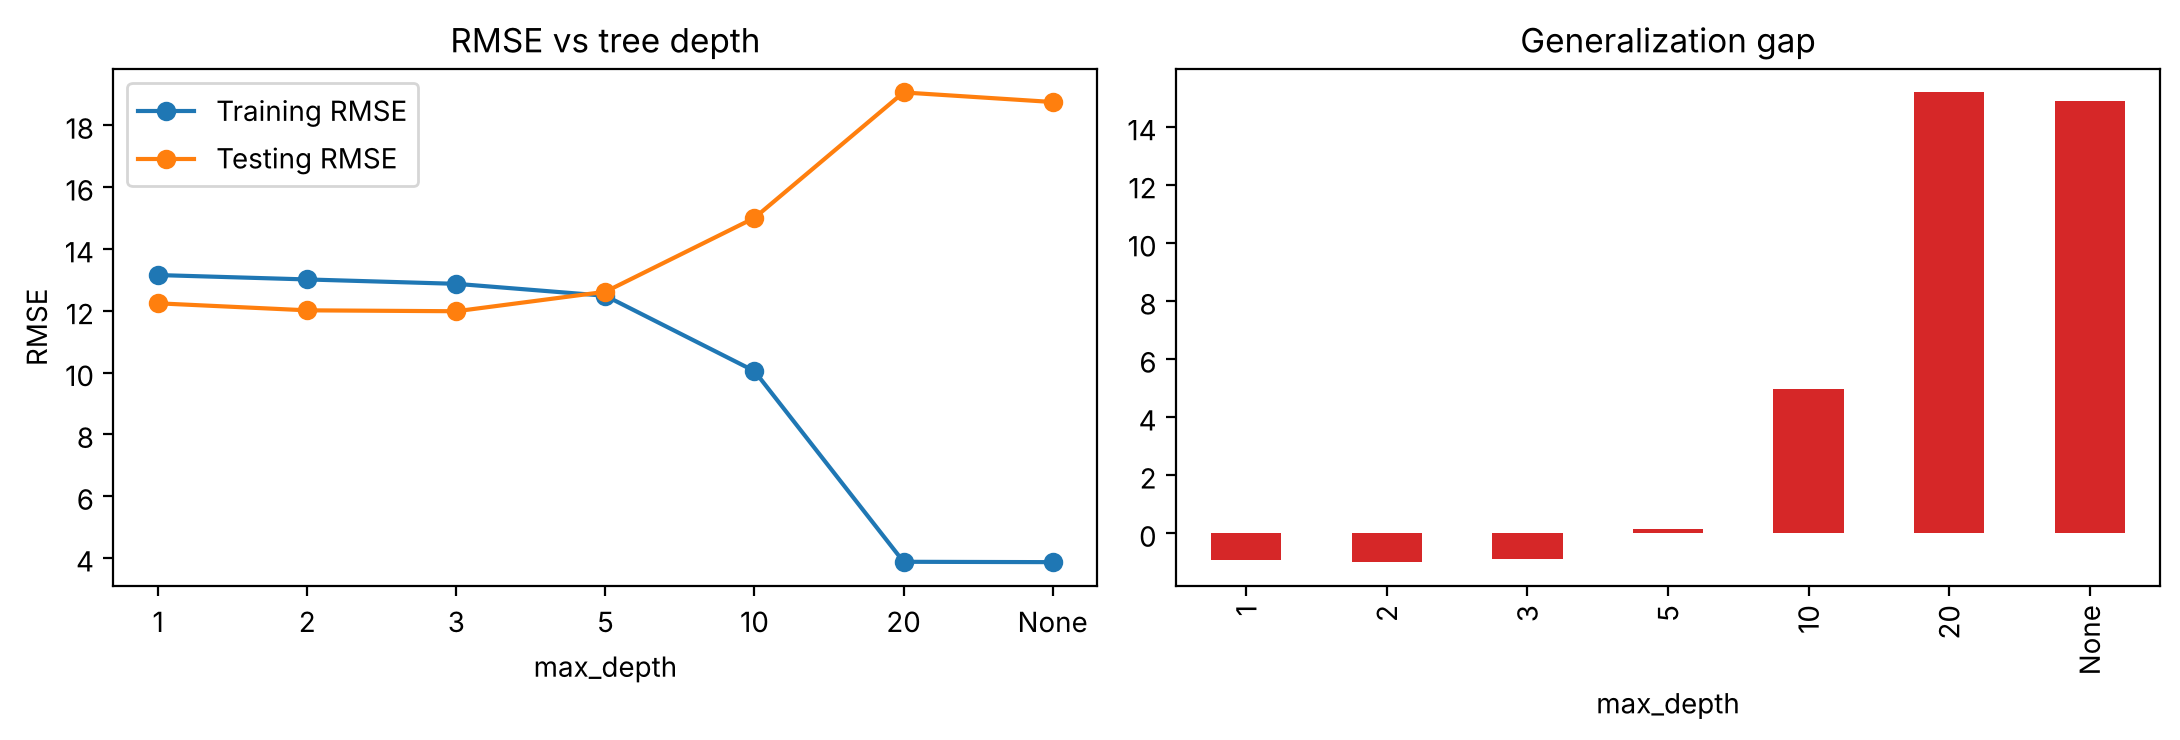

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
c1[["Training RMSE", "Testing RMSE"]].plot(marker="o", ax=ax[0], title="RMSE vs tree depth"); ax[0].set_ylabel("RMSE")
c1["Gap (test - train)"].plot(kind="bar", color="tab:red", ax=ax[1], title="Generalization gap"); plt.tight_layout(); plt.show()

In [33]:
best = c1["Testing RMSE"].idxmin()
print("Lowest testing RMSE at max_depth =", best, "-> overfitting starts for deeper trees (gap keeps growing).")

Lowest testing RMSE at max_depth = 3 -> overfitting starts for deeper trees (gap keeps growing).


In [34]:
# C.2
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

In [35]:
tscv = TimeSeriesSplit(n_splits=5)
scoring = "neg_root_mean_squared_error"

In [36]:

degrees = [1, 2, 3, 4, 5, 6]
cv_rmse = []
for deg in degrees:
    pipe = make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(), LinearRegression())
    cv_rmse.append(-cross_val_score(pipe, X_train[NUM], y_train, cv=tscv, scoring=scoring).mean())

,CV RMSE
degree,
1,13.130
2,13.537
3,15.287
4,35.729
5,111.313
6,214.813


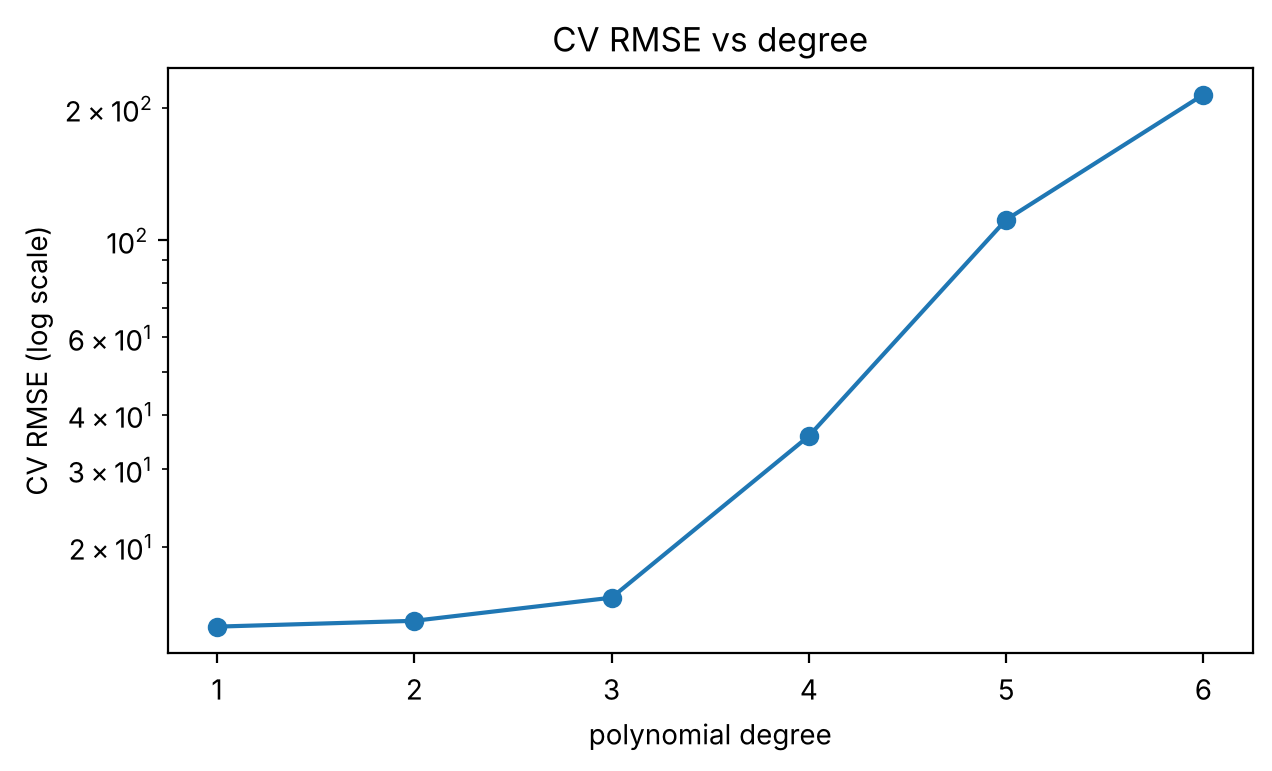

Best degree: 1


In [37]:
display(pd.DataFrame({"degree": degrees, "CV RMSE": cv_rmse}).set_index("degree").round(3))
plt.figure(figsize=(7, 3.8)); plt.plot(degrees, cv_rmse, "o-"); plt.yscale("log")
plt.xlabel("polynomial degree"); plt.ylabel("CV RMSE (log scale)"); plt.title("CV RMSE vs degree"); plt.show()
print("Best degree:", degrees[int(np.argmin(cv_rmse))])

In [38]:
# D.1
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.ensemble import GradientBoostingRegressor

In [39]:
school_options = {
    "Rare-category grouping":        lambda: OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist", sparse_output=False),
    "Target encoding (out-of-fold)": lambda: TargetEncoder(target_type="continuous", cv=5, random_state=SEED),
    "Feature removal":               lambda: "drop",
}

In [40]:
def make_prep(option):

    return ColumnTransformer([("school", school_options[option](), ["school_code"])], remainder="passthrough")

Xtr_d, Xte_d = train[NUM + ["school_code"]], test[NUM + ["school_code"]]      

In [41]:
rows = []
for option in school_options:
    pipe = make_pipeline(make_prep(option), GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=SEED))
    cv = -cross_val_score(pipe, Xtr_d, y_train, cv=tscv, scoring=scoring).mean()
    pipe.fit(Xtr_d, y_train)
    rows.append([option, cv, rmse(y_train, pipe.predict(Xtr_d)), rmse(y_test, pipe.predict(Xte_d))])

In [42]:
d1 = pd.DataFrame(rows, columns=["Approach", "CV RMSE (train)", "Training RMSE", "Testing RMSE"]).set_index("Approach")
display(d1.round(3))
best_school = d1["CV RMSE (train)"].idxmin()
print("Treatment chosen by cross-validation:", best_school)

,CV RMSE (train),Training RMSE,Testing RMSE
Approach,,,
Rare-category grouping,14.118,11.814,11.974
Target encoding (out-of-fold),13.961,12.993,12.402
Feature removal,13.948,12.403,12.044


Treatment chosen by cross-validation: Feature removal


In [43]:
# D.2
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV

alphas = [0.001, 0.01, 0.1, 1, 10, 100]
Xn_train, Xn_test = X_train[NUM], X_test[NUM]

In [44]:
def poly_model(model, degree=5):
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), model)

lr_cv = -cross_val_score(poly_model(LinearRegression()), Xn_train, y_train, cv=tscv, scoring=scoring).mean()

In [45]:
searches = {}
for name, model in [("Ridge", Ridge()), ("Lasso", Lasso(max_iter=20000))]:
    gs = GridSearchCV(poly_model(model), {f"{name.lower()}__alpha": alphas}, cv=tscv, scoring=scoring)
    searches[name] = gs.fit(Xn_train, y_train)

In [46]:
table = pd.DataFrame({"alpha": alphas})
for name, gs in searches.items():
    table[name + " CV RMSE"] = -gs.cv_results_["mean_test_score"]
display(table.set_index("alpha").round(3))
print(f"Linear Regression (no penalty): CV RMSE = {lr_cv:.3f}")

,Ridge CV RMSE,Lasso CV RMSE
alpha,,
0.001,23.190,18.344
0.010,18.038,15.170
0.100,15.745,13.588
1.000,14.538,13.123
10.000,13.828,13.497
100.000,13.381,13.497


Linear Regression (no penalty): CV RMSE = 111.313


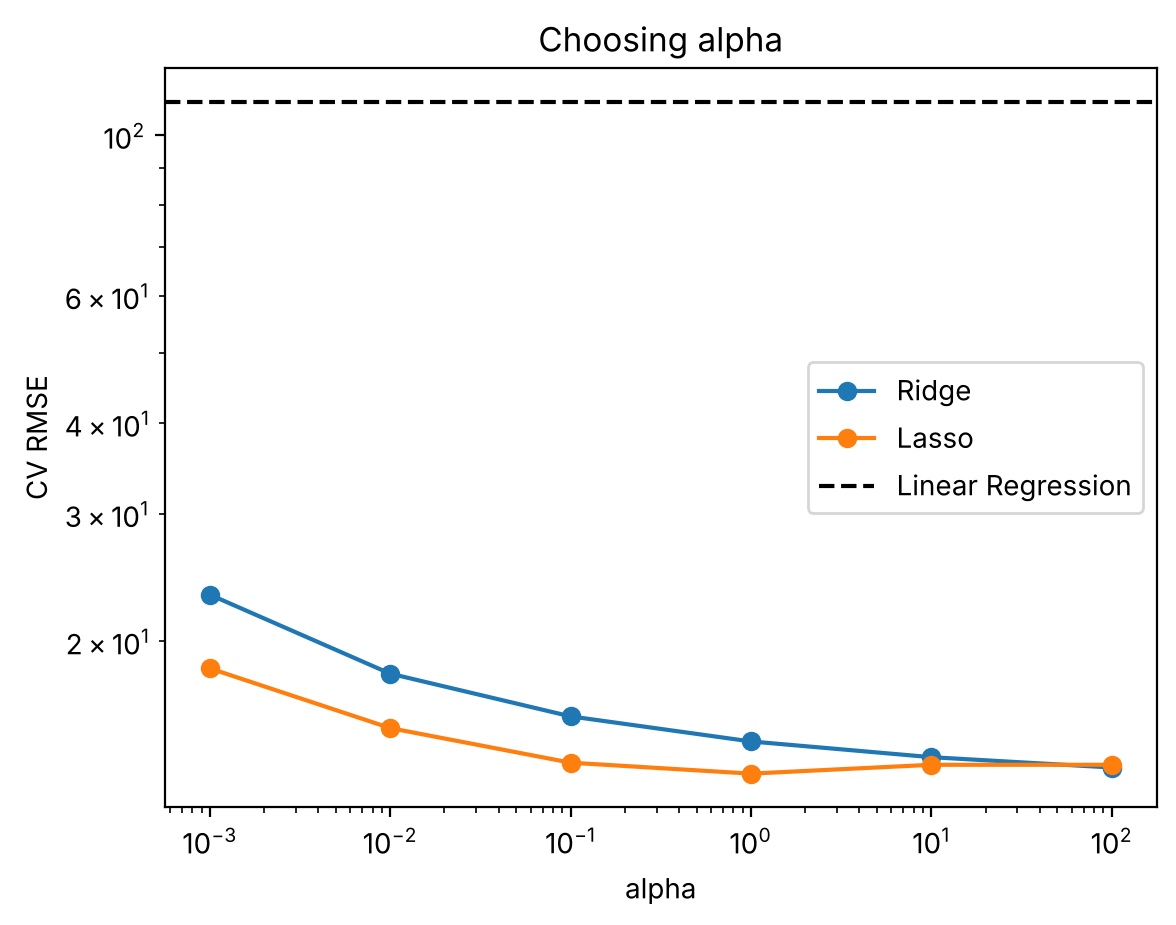

In [47]:
for name, gs in searches.items():
    plt.plot(alphas, -gs.cv_results_["mean_test_score"], "o-", label=name)
plt.axhline(lr_cv, color="k", ls="--", label="Linear Regression")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("alpha"); plt.ylabel("CV RMSE"); plt.legend(); plt.title("Choosing alpha"); plt.show()

In [48]:

fits = {"Linear Regression": poly_model(LinearRegression()).fit(Xn_train, y_train)}
for name, gs in searches.items():
    fits[f"{name} (alpha={list(gs.best_params_.values())[0]})"] = gs.best_estimator_

In [49]:
rows = []
for name, m in fits.items():
    c = m[-1].coef_
    rows.append([name, len(c), int((np.abs(c) > 1e-8).sum()), np.abs(c).max(), np.linalg.norm(c)])
display(pd.DataFrame(rows, columns=["Model", "n coefficients", "non-zero", "max |coef|", "L2 norm"]).set_index("Model").round(3))

,n coefficients,non-zero,max |coef|,L2 norm
Model,,,,
Linear Regression,251,251,1870.753,7193.366
Ridge (alpha=100),251,251,0.863,3.140
Lasso (alpha=1),251,5,1.261,1.533


In [50]:
# D.4
lr_scores = {deg: -cross_val_score(poly_model(LinearRegression(), deg), Xn_train, y_train, cv=tscv, scoring=scoring).mean()
             for deg in [1, 2, 3, 5]}
best_deg = min(lr_scores, key=lr_scores.get)
lin = poly_model(LinearRegression(), best_deg)

In [51]:
reg_name = max(searches, key=lambda k: searches[k].best_score_)
reg = searches[reg_name].best_estimator_

In [52]:
tree_gs = GridSearchCV(make_pipeline(make_prep(best_school), DecisionTreeRegressor(random_state=SEED)),
                       {"decisiontreeregressor__max_depth": [2, 3, 4, 5, 6, 8, 10],
                        "decisiontreeregressor__min_samples_leaf": [1, 5, 10, 20]},
                       cv=tscv, scoring=scoring).fit(Xtr_d, y_train)

In [53]:
gb = make_pipeline(make_prep(best_school),
                   GradientBoostingRegressor(n_estimators=1000, learning_rate=0.05, max_depth=3,
                                             validation_fraction=0.15, n_iter_no_change=20, random_state=SEED))
gb.fit(Xtr_d, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('gradientboostingregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['study_hours','sleep_hours','stress_level','daily_productivity', 'energy_level','school_code']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('school', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pa

In [54]:
print("Linear Regression degree :", best_deg)
print("Regularized model        :", reg_name, "| alpha =", list(searches[reg_name].best_params_.values())[0])
print("Decision tree parameters :", tree_gs.best_params_)
print("Boosting: early stopping used", gb[-1].n_estimators_, "trees out of 1000")

Linear Regression degree : 1
Regularized model        : Lasso | alpha = 1
Decision tree parameters : {'decisiontreeregressor__max_depth': 2, 'decisiontreeregressor__min_samples_leaf': 20}
Boosting: early stopping used 30 trees out of 1000


In [55]:
from sklearn.metrics import r2_score

def report(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    tr, te = rmse(y_train, model.predict(Xtr)), rmse(y_test, model.predict(Xte))
    return [name, tr, te, r2_score(y_test, model.predict(Xte)), te - tr]

In [56]:
final = pd.DataFrame([
    report(f"Linear Regression (degree {best_deg})", lin, Xn_train, Xn_test),
    report(f"{reg_name} (degree 5)", reg, Xn_train, Xn_test),
    report("Decision Tree", tree_gs.best_estimator_, Xtr_d, Xte_d),
    report("Gradient Boosting", gb, Xtr_d, Xte_d),
], columns=["Model", "Training RMSE", "Testing RMSE", "Testing R2", "Gap"]).set_index("Model")
display(final.round(3))

,Training RMSE,Testing RMSE,Testing R2,Gap
Model,,,,
Linear Regression (degree 1),13.038,12.130,0.051,-0.907
Lasso (degree 5),13.057,12.126,0.052,-0.931
Decision Tree,13.011,12.012,0.069,-0.999
Gradient Boosting,12.880,12.020,0.068,-0.860


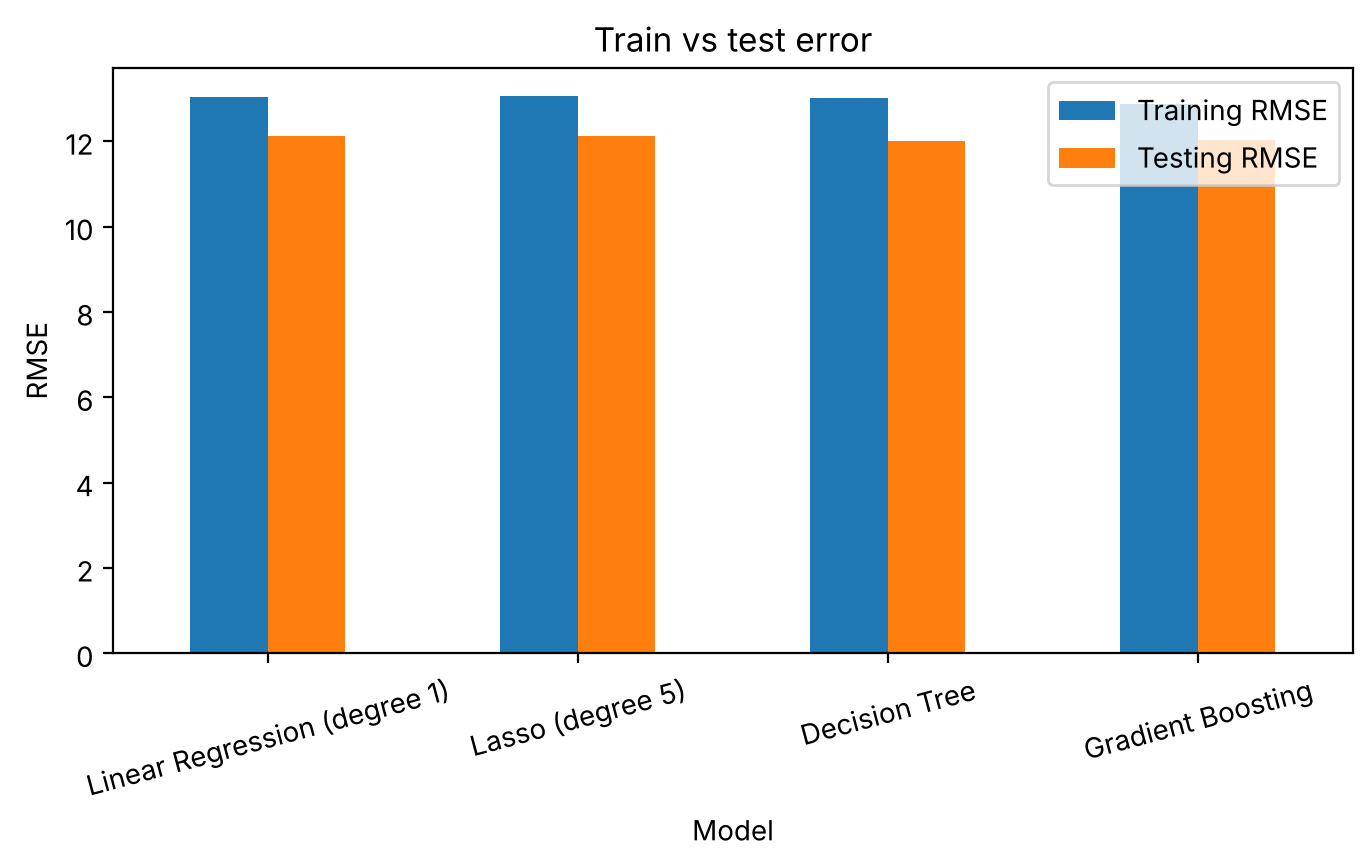

In [57]:
final[["Training RMSE", "Testing RMSE"]].plot(kind="bar", figsize=(8, 3.8), title="Train vs test error", rot=15)
plt.ylabel("RMSE"); plt.show()

In [58]:
# Final discussion
best_model = final["Testing RMSE"].idxmin()
big_gap = final["Gap"].idxmax()
deep = c1.loc["None"]
tuned = final.loc["Decision Tree"]

In [59]:
print(f"1. Best generalization : {best_model} (test RMSE {final.loc[best_model, 'Testing RMSE']:.2f}, R2 {final.loc[best_model, 'Testing R2']:.3f})")
print(f"2. Largest gap         : {big_gap} (train {final.loc[big_gap, 'Training RMSE']:.2f} -> test {final.loc[big_gap, 'Testing RMSE']:.2f}, gap {final.loc[big_gap, 'Gap']:.2f})")
print("3. What reduced overfitting:")
print(f"   - tree complexity control : gap {deep['Gap (test - train)']:.2f} (no limit) -> {tuned['Gap']:.2f} (tuned)")
print(f"   - regularization          : CV RMSE {lr_cv:.2f} (plain degree 5) -> {-searches[reg_name].best_score_:.2f} ({reg_name})")
print(f"   - early stopping          : {gb[-1].n_estimators_} trees instead of 1000")
print(f"   - school_code treatment   : {best_school}")

1. Best generalization : Decision Tree (test RMSE 12.01, R2 0.069)
2. Largest gap         : Gradient Boosting (train 12.88 -> test 12.02, gap -0.86)
3. What reduced overfitting:
   - tree complexity control : gap 14.88 (no limit) -> -1.00 (tuned)
   - regularization          : CV RMSE 111.31 (plain degree 5) -> 13.12 (Lasso)
   - early stopping          : 30 trees instead of 1000
   - school_code treatment   : Feature removal


**4. Why select models with validation performance, not training performance?**
Training error is optimistic by construction: the model was fitted on those rows, so a more complex model can always lower it (an unconstrained tree reaches ≈ 0) without being more useful. Validation error uses rows the model did not see, so it estimates the error on new students and has a minimum at the right complexity. Choosing by training error would always pick the most overfitted model.

**5. Why must the final test set stay untouched during model selection?**
Each time we look at the test score and change something (depth, α, features, model), information from the test set leaks into our choices and the test set becomes a second validation set. The final score is then optimistically biased and no longer says how the model will behave on truly new data. Using the test set only once, at the end, gives an unbiased estimate of generalization error.